In [11]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [10]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from scipy import ndimage
import scipy.signal as signal
import pickle
import math
import pygame
import cv2

from notebooks.imports import *
from src.utils import pmf_utils

from scripts.ucla_rdk import DotMotionStim as RDK_ucla
from scripts.uw_rdk_prelim import RandomDotMotion as RDK_uw
from scripts import motion_energy

### Config

In [12]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Load and Preprocess data

In [4]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)


# convert pulse info to frame units
convert_to_frame = 1000 / 16.67
data["pulse_onset_frame"] = np.round(data.pulse_onset * convert_to_frame) + 1
data["pulse_offset_frame"] = np.round(data.pulse_onset_frame + (data.pulse_duration * convert_to_frame))
data["rt_frame"] = np.ceil(data.reaction_time * convert_to_frame) + 1

data

,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,stimulus_seed,pulse_type,pulse_onset_frame,pulse_offset_frame,rt_frame
0,0,uw,DBM11,10_1,1,0,False,100,1,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.416750,0.066680,-100,612658,-3.0,26.0,30.0,66.0
1,0,uw,DBM11,10_1,2,0,False,100,1,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.416750,0.066680,100,463182,0.0,26.0,30.0,30.0
2,0,uw,DBM11,10_1,3,0,False,-100,-1,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.416750,0.066680,100,165712,3.0,26.0,30.0,132.0
3,0,uw,DBM11,10_1,4,0,False,-100,-1,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.050010,0.066680,-100,418800,-0.0,4.0,8.0,30.0
4,0,uw,DBM11,10_1,5,0,False,-100,-1,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.233380,0.066680,-100,372882,-0.0,15.0,19.0,60.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,297,ucla,PSUIM9,9_1,346,0,False,18,1,1,1.108688,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.029568,0.050560,100,346,1.0,3.0,6.0,68.0
113870,297,ucla,PSUIM9,9_1,347,0,False,36,1,1,1.598707,1.0,2.6,1.000000,60.0,0.5,0.250000,False,NaN,NaN,0,347,0.0,NaN,NaN,97.0
113871,297,ucla,PSUIM9,9_1,348,0,False,-9,-1,1,2.292042,0.0,0.0,1.000000,60.0,1.5,0.252608,False,NaN,NaN,0,348,0.0,NaN,NaN,139.0
113872,297,ucla,PSUIM9,9_1,349,0,False,36,1,1,1.706793,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.240538,0.050291,100,349,2.0,15.0,18.0,104.0


### Utils

### Helper Functions

In [15]:
rdk_ucla = RDK_ucla()
rdk_uw = RDK_uw()

In [13]:
def draw_stimulus(screen, rdk):
	"""Draw the stimulus on the screen."""
	screen.fill((0, 0, 0))  # Clear screen before drawing
	for ind in range(len(rdk.x)):
		pygame.draw.circle(screen, rdk.color, (rdk.x[ind], rdk.y[ind]), rdk.radius)

def get_stimulus_array(screen, rdk, pars, rt_frame, down_sample_fact=10):
	resolution = (int(rdk.stimulus_size[1] / down_sample_fact), int(rdk.stimulus_size[0] / down_sample_fact))
	stimulus_array = np.zeros((resolution[1], resolution[0], rt_frame))

	# stimulus_array[0] = cv2.resize(pygame.surfarray.array2d(screen).astype(np.uint8), resolution)
	pulses = pars.get("pulse", ([], []))

	for i in range(rt_frame):
		if i==0:
			rdk.new_stimulus(pars)  # Initialize the stimulus
		elif pulses and i == pulses[0][0] - 1:
			rdk.move_dots(new_coherence=pulses[0][1])
			pulses.pop(0)
		else:
			rdk.move_dots()

		draw_stimulus(screen, rdk)
		stimulus_array[:,:,i] = pygame.surfarray.array2d(screen).astype(np.uint8)
		# stimulus_array[i] = cv2.resize(stimulus_array[i], resolution)
	stimulus_array /= np.max(stimulus_array)

	return stimulus_array.astype(np.uint8)


In [17]:
# Initialize Pygame
pygame.init()
screen = pygame.display.set_mode((1280, 720))


rt_frame = 12
# Parameters for stimulus
pulse_onset, pulse_coherence, pulse_offset, signed_coherence = 3, -100, 7, 100
pars = {
	"seed": 0,
	"coherence": 100,
	"pulse": [(3, -100), (7, 100), (10, -100)],
}
stimulus_array = get_stimulus_array(screen, rdk_uw, pars, rt_frame, down_sample_fact=1)

print("Loaded 3D Array Shape:", stimulus_array.shape)

pygame.quit()

ALSA lib confmisc.c:855:(parse_card) cannot find card '0'
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_card_inum returned error: No such file or directory
ALSA lib confmisc.c:422:(snd_func_concat) error evaluating strings
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_concat returned error: No such file or directory
ALSA lib confmisc.c:1334:(snd_func_refer) error evaluating name
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_refer returned error: No such file or directory
ALSA lib conf.c:5701:(snd_config_expand) Evaluate error: No such file or directory
ALSA lib pcm.c:2664:(snd_pcm_open_noupdate) Unknown PCM default


Loaded 3D Array Shape: (1280, 720, 12)


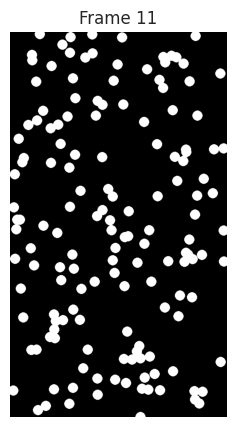

In [18]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Initialize the figure and axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis("off")  # Hide axes

# Set up the first frame (to be updated during animation)
im = ax.imshow(stimulus_array[:,:,0], cmap="gray")
ax.set_title("Frame 0")

# Function to update each frame in the animation
def update(frame):
	im.set_data(stimulus_array[:,:,frame])  # Update the image with the new frame
	ax.set_title(f"Frame {frame}")  # Update the title with the frame number
	return [im]

ani = FuncAnimation(fig, update, frames=stimulus_array.shape[2], interval=50, blit=True)
HTML(ani.to_jshtml())


# Tutorial

In [14]:
import numpy as np
from numpy.fft import fftn, fftshift, fftfreq
from scipy.ndimage import rotate
import seaborn as sns
import matplotlib.pyplot as plt
from ipywidgets import interact
import scripts.motion_energy as me

%matplotlib inline
sns.set_theme(font_scale=1.3, color_codes=True)

interactive(children=(FloatSlider(value=0.30000000000000004, description='σ_c', max=0.6, min=0.1, step=0.05), …

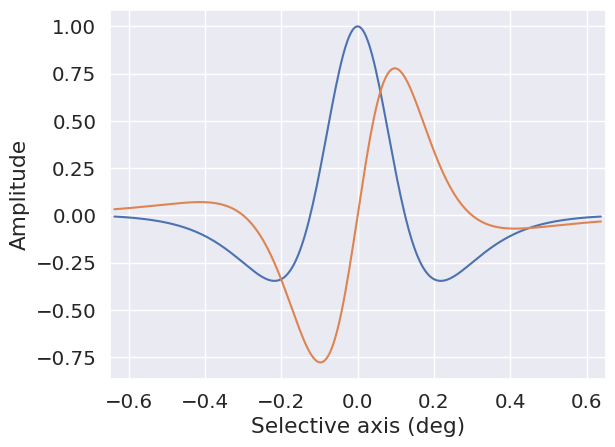

In [11]:
@interact
def cauchy_param_tutorial(σ_c=(0.1, 0.6, 0.05)):
	"""Interactive widget to demo spatial component of filters."""
	x = me.filter_grid(256, 0.005, center=True)
	f1, f2 = me.cauchy(x, σ_c)
	f, ax = plt.subplots()
	ax.plot(x, f1, x, f2)
	ax.set(xlim=(-0.65, 0.65), xlabel="Selective axis (deg)", ylabel="Amplitude")


In [12]:
def centered_colormap(data):
	"""Set vmin and vmax to put center of colormap at 0."""
	lim = np.abs([data.min(), data.max()]).max()
	return dict(vmin=-lim, vmax=+lim, cmap="icefire")

interactive(children=(FloatSlider(value=0.35, description='σ_c', max=0.65, min=0.05), FloatSlider(value=0.1, d…

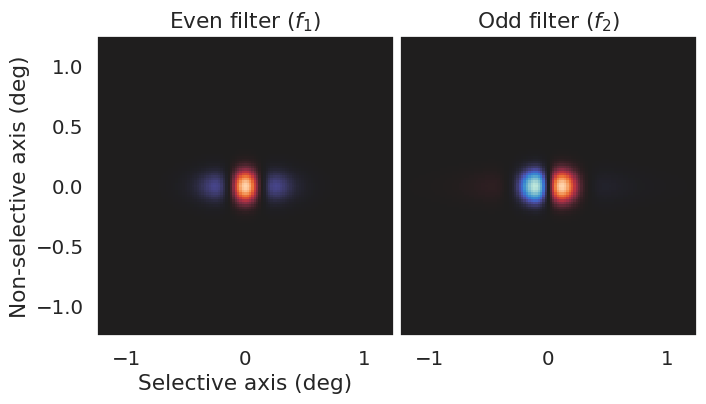

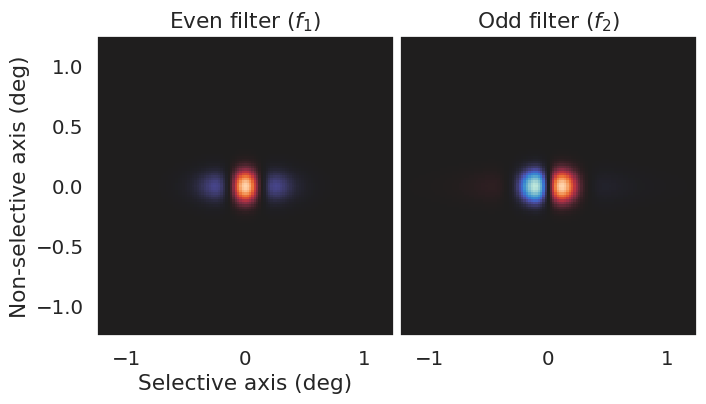

In [ ]:
@interact
def spatial_param_tutorial(σ_c=(0.05, 0.65), σ_g=(0.02, 0.2, 0.02), θ=(-90, 90, 10)):
	"""Interactive widget to demo full spatial component of filters."""
	x = me.filter_grid(125, 0.02, True)
	xx, yy = np.meshgrid(x, x)

	c1, c2 = me.cauchy(x, σ_c, 4)
	g = me.gaussian_envelope(x, σ_g)

	qx1, qy = np.meshgrid(c1, g)
	qx2, qy = np.meshgrid(c2, g)
	filters = ("Even filter ($f_1$)", qx1), ("Odd filter ($f_2$)", qx2)

	f, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True)
	for ax, (title, filt) in zip(axes, filters):
		filt = rotate(filt * qy, θ, reshape=False)
		ax.pcolormesh(xx, yy, filt, **centered_colormap(filt))
		ax.set(title=title)

	f.subplots_adjust(0, 0, 1, 1, 0.02)
	axes[0].set(xlabel="Selective axis (deg)", ylabel="Non-selective axis (deg)")


interactive(children=(IntSlider(value=50, description='k', max=70, min=30, step=5), Output()), _dom_classes=('…

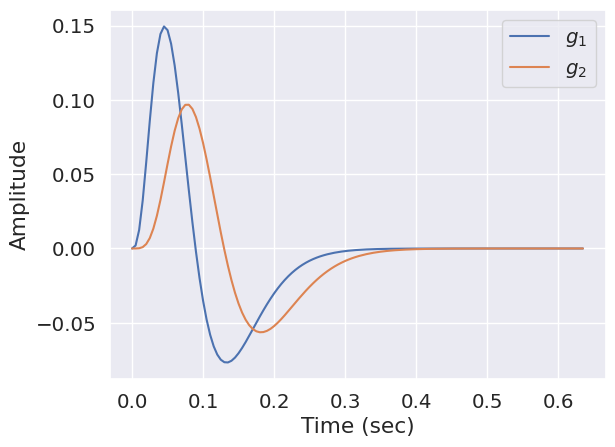

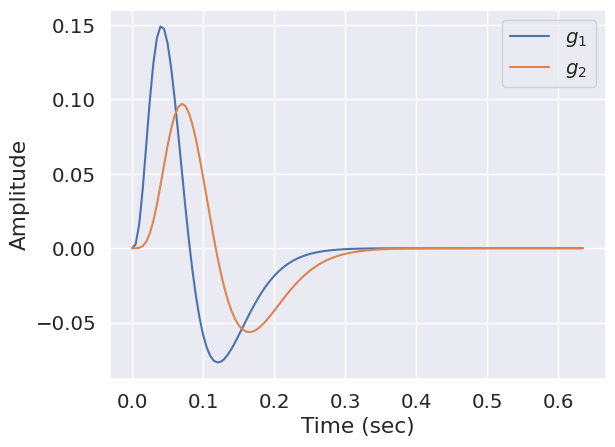

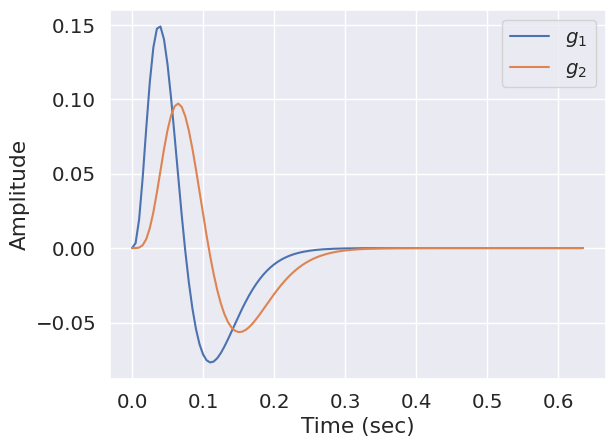

In [16]:
@interact
def temporal_param_tutorial(k=(30, 70, 5)):
	"""Interactive widget to demo temporal component of filters."""
	t = me.filter_grid(128, 0.005)
	f1 = me.temporal_impulse_response(t, 3, k)
	f2 = me.temporal_impulse_response(t, 5, k)
	f, ax = plt.subplots()
	lines = ax.plot(t, f1, t, f2)
	ax.legend(lines, ["$g_1$", "$g_2$"])
	ax.set(xlabel="Time (sec)", ylabel="Amplitude")


# XXX

In [ ]:
def generate_pulse_sequence(self):
	pulse_prob = self.pulse_probabilities[self.signed_coherence]
	cumulative_a = np.cumsum(pulse_prob)
	index = np.argmax(cumulative_a >= np.random.uniform())

	if index < 3:
		self.pulse_coherence = -100
	elif index < 6:
		self.pulse_coherence = 100
	else:
		self.pulse_coherence = self.signed_coherence

	if index % 3 == 0:
		self.pulse_onset = self.config.TASK["stimulus"]["pulse_onset"]["value"]["early"]
	elif index % 3 == 1:
		self.pulse_onset = self.config.TASK["stimulus"]["pulse_onset"]["value"]["middle"]
	else:
		self.pulse_onset = self.config.TASK["stimulus"]["pulse_onset"]["value"]["late"]

	pulse = [(int(self.pulse_onset), self.pulse_coherence), (int(self.pulse_onset) + int(self.pulse_duration), self.signed_coherence)]

	return pulse


def initiate_stimulus(self, args):
	self.frame_counter = 0
	args.update(self.initiate_stimulus_config["dots"])
	self.stimulus.new_stimulus(args)


def update_stimulus(self, args=None):
	frame_rate = self.clock.get_fps() or self.frame_rate
	# pulse = [(frame, coherence), (frame, coherence), ...]
	if args and "pulse" in args and args["pulse"]:
		if self.frame_counter == args["pulse"][0][0]:
			self.stimulus.move_dots(frame_rate=frame_rate, new_coherence=args["pulse"][0][1])
			args["pulse"].pop(0)
		else:
			self.stimulus.move_dots(frame_rate=frame_rate)
	else:
		self.stimulus.move_dots(frame_rate=frame_rate)
	self.frame_counter += 1

	func = self.draw_stimulus
	args = {
		"ndots": self.stimulus.nDots,
		"xpos": self.stimulus.x,
		"ypos": self.stimulus.y,
		"radius": [self.stimulus.radius] * self.stimulus.nDots,
		"color": [self.stimulus.color] * self.stimulus.nDots,
	}
	return func, args

---
---

In [5]:
## RDK with pulse
import pickle
import math
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from src.utils.StimtoArray import get_RDK

def f1(x, y, sigma_c=0.35, sigma_g=0.05):
	alpha = np.arctan(x / sigma_c)
	return (np.cos(alpha) ** 4) * (np.cos(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))


def f2(x, y, sigma_c=0.35, sigma_g=0.05):
	alpha = np.arctan(x / sigma_c)
	return (np.cos(alpha) ** 4) * (np.sin(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))


def g1(t):
	return ((60 * t) ** 3) * (np.exp(-60 * t)) * ((1 / math.factorial(3)) - (((60 * t) ** 2) / math.factorial(3 + 2)))


def g2(t):
	return ((60 * t) ** 5) * (np.exp(-60 * t)) * ((1 / math.factorial(5)) - (((60 * t) ** 2) / math.factorial(5 + 2)))


def create_filters(savename="spatiotemporal_filters", nFrames=360):
	x_space = np.arange(-0.7, 0.7, 0.05)
	y_space = np.arange(-0.7, 0.7, 0.05)
	t_space = np.arange(0, 0.2, 0.01)
	# t_space = np.linspace(0,1000,nFrames)/1000

	# Linear Spatiotemporal Filter (XT) at specific Y value
	Filter_XT_left1 = np.empty((len(t_space), len(x_space), len(y_space)))
	Filter_XT_left2 = np.empty((len(t_space), len(x_space), len(x_space)))
	Filter_XT_right1 = np.empty((len(t_space), len(x_space), len(x_space)))
	Filter_XT_right2 = np.empty((len(t_space), len(x_space), len(x_space)))
	for i, t in enumerate(t_space):
		for j, x in enumerate(x_space):
			Filter_XT_right1[i, j, :] = f1(x, y_space) * g1(t) + f2(x, y_space) * g2(t)
			Filter_XT_right2[i, j, :] = f2(x, y_space) * g1(t) - f1(x, y_space) * g2(t)
			Filter_XT_left1[i, j, :] = f1(x, y_space) * g1(t) - f2(x, y_space) * g2(t)
			Filter_XT_left2[i, j, :] = f2(x, y_space) * g1(t) + f1(x, y_space) * g2(t)


	return Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2


# @jit(nopython=True,parallel=True)
def Calculate_ME(RDK_processed, Coh):
	for i, _coh in enumerate(Coh):
		print(i + 1, "/", len(Coh))
		# RDK = get_RDK(coh=coh,seed=1,nFrames=frames)
		#
		# RDK /= np.max(RDK)  # Converting and normalizing matrix for grayscale image
		# RDK_processed = np.zeros((frames,192,108))
		# for i in range(frames):
		#     RDK_processed[i,:,:] = cv2.resize(RDK[i,:,:],(108,192))

		## Convolution
		ME_right1 = ndimage.convolve(RDK_processed[i], Filter_XT_right1, mode="constant", cval=0.0)
		ME_right2 = ndimage.convolve(RDK_processed[i], Filter_XT_right2, mode="constant", cval=0.0)
		ME_left1 = ndimage.convolve(RDK_processed[i], Filter_XT_left1, mode="constant", cval=0.0)
		ME_left2 = ndimage.convolve(RDK_processed[i], Filter_XT_left2, mode="constant", cval=0.0)

		ME_RIGHT = (ME_right1**2) + (ME_right2**2)
		ME_LEFT = (ME_left1**2) + (ME_left2**2)
		ME = ME_RIGHT - ME_LEFT

		ME_XT = np.mean(ME, axis=2)
		ME_T = np.mean(ME_XT, axis=1)

		ME_T_ms[i, :] = np.repeat(ME_T, 16)

	return ME_T_ms, ME_T

In [ ]:
def create_stimulus(Coh, pulse_coh, pulse_dur, pulse_t, filename="RDKPulse_position_matrix_processed"):
	RDK_processed = np.zeros((len(Coh), frames, 192, 108))
	for i_coh, coh in enumerate(Coh):
		RDK = get_RDK(coh=coh, seed=1, nFrames=frames, pulse_coh=pulse_coh[i_coh], pulse_t=pulse_t[i_coh], pulse_dur=pulse_dur[i_coh])

		RDK /= np.max(RDK)  # Converting and normalizing matrix for grayscale image
		for t in range(frames):
			RDK_processed[i_coh, t, :, :] = cv2.resize(RDK[t, :, :], (108, 192))

	np.savez(filename + ".npz", RDK_processed=RDK_processed, Coh=Coh)
	return RDK_processed, Coh

frames = 360
filename = "RDKPulseFixed_position_matrix_processed"
# Coh = [-100, -70, -36, -18, -9, 0, 9, 18, 36, 70, 100]
Coh = [-100, 0, 100]
pulse_coh = [-100, -100, -100]
pulse_t = np.ones(len(Coh)) * 150
pulse_dur = np.ones(len(Coh)) * 30
RDK_processed, Coh = create_stimulus(Coh=Coh, filename=filename, pulse_coh=pulse_coh, pulse_dur=pulse_dur, pulse_t=pulse_t)

pygame 2.6.1 (SDL 2.28.4, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


ALSA lib confmisc.c:855:(parse_card) cannot find card '0'
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_card_inum returned error: No such file or directory
ALSA lib confmisc.c:422:(snd_func_concat) error evaluating strings
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_concat returned error: No such file or directory
ALSA lib confmisc.c:1334:(snd_func_refer) error evaluating name
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_refer returned error: No such file or directory
ALSA lib conf.c:5701:(snd_config_expand) Evaluate error: No such file or directory
ALSA lib pcm.c:2664:(snd_pcm_open_noupdate) Unknown PCM default
ALSA lib confmisc.c:855:(parse_card) cannot find card '0'
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_card_inum returned error: No such file or directory
ALSA lib confmisc.c:422:(snd_func_concat) error evaluating strings
ALSA lib conf.c:5178:(_snd_config_evaluate) function snd_func_concat returned error: No su

In [3]:
Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2 = create_filters()

In [6]:
frames = 360

global ME_T_ms
ME_T_ms = np.zeros((len(Coh), frames * 16))

ME_T_ms, ME_T = Calculate_ME(RDK_processed, Coh)

1 / 3
2 / 3
3 / 3


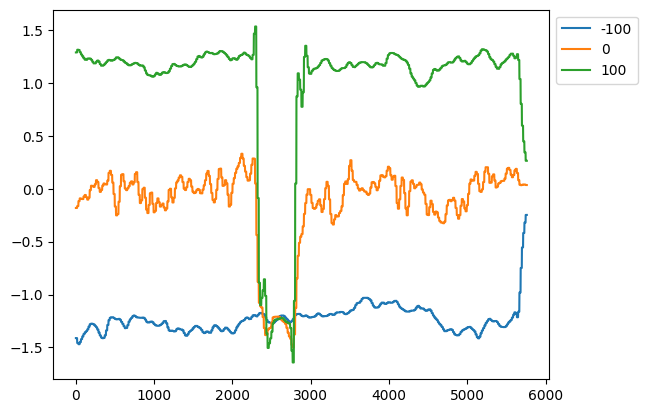

In [7]:

np.savez("Motion_Energy_all_pulse_fixed.npz", Motion_Energy=ME_T_ms, Motion_Energy_frames=ME_T, RDK_processed=RDK_processed, Coh=Coh, Pulse_Dur=pulse_dur, Pulse_time=pulse_t, Pulse_coh=pulse_coh)

import matplotlib.pyplot as plt

for i, coh in enumerate(Coh):
	plt.plot(ME_T_ms[i, :], label=str(coh))
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

In [21]:
stimulus_array.shape, RDK_processed.shape


((1280, 720, 12), (3, 360, 192, 108))

In [40]:
stimulus_array_processed = stimulus_array.reshape(stimulus_array.shape[2], stimulus_array.shape[0], stimulus_array.shape[1]).astype(np.float32)
stimulus_array_processed /= np.max(stimulus_array_processed)
stimulus_array_processed.shape

(12, 1280, 720)

In [41]:
import cv2
import numpy as np

# Define new size
scale_factor = 0.1  # 10% of original size
new_height = int(stimulus_array_processed.shape[1] * scale_factor)
new_width = int(stimulus_array_processed.shape[2] * scale_factor)

# Create an empty list to store resized frames
resized_frames = []

# Loop through each frame and resize it
for t in range(len(stimulus_array_processed)):
	resized_frame = cv2.resize(stimulus_array_processed[t, :, :], (new_width, new_height))
	resized_frames.append(resized_frame)

# Convert list back to numpy array
stimulus_array_processed = np.array(resized_frames)

print("New shape:", stimulus_array_processed.shape)  # Should be (t, new_height, new_width)


New shape: (12, 128, 72)


In [43]:
ME_right1 = ndimage.convolve(stimulus_array_processed, Filter_XT_right1, mode="constant", cval=0.0)
ME_right2 = ndimage.convolve(stimulus_array_processed, Filter_XT_right2, mode="constant", cval=0.0)
ME_left1 = ndimage.convolve(stimulus_array_processed, Filter_XT_left1, mode="constant", cval=0.0)
ME_left2 = ndimage.convolve(stimulus_array_processed, Filter_XT_left2, mode="constant", cval=0.0)

ME_RIGHT = (ME_right1**2) + (ME_right2**2)
ME_LEFT = (ME_left1**2) + (ME_left2**2)
ME = ME_RIGHT - ME_LEFT

In [44]:
ME_XT = np.mean(ME, axis=2)
ME_T = np.mean(ME_XT, axis=1)

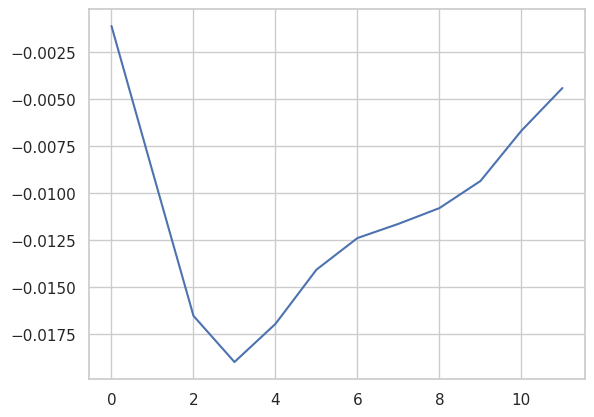

In [45]:
plt.plot(ME_T)